# DBSCAN vs K-Means - Linear and Non-linear Clusters
**Datasets:** Iris (`load_iris`) and two interleaving half-moons (`make_moons`)
**Covers:** density-based clustering, `eps` / `min_samples`, noise points, and why K-Means (spherical clusters) fails on non-linear shapes that DBSCAN separates.

In [1]:
from sklearn.datasets import load_iris
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [2]:
iris = load_iris()

X = iris.data
y  =iris.target

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

<Axes: >

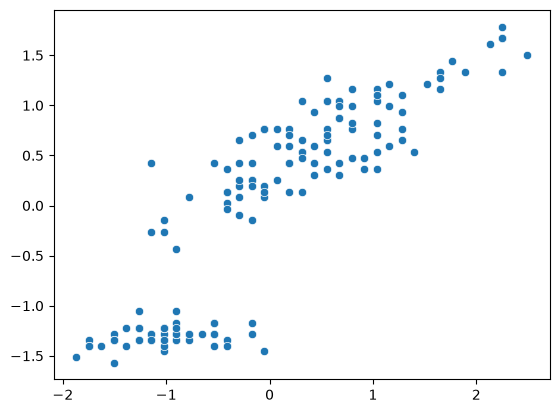

In [4]:
# visualize
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:,2])

## DBSCAN on Iris
DBSCAN groups points that have at least `min_samples` neighbours within radius `eps`; points in sparse regions are labelled **noise (-1)**.

In [5]:
# DBSCAN

from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps = 0.8,
    min_samples = 5
)

In [6]:
labels = dbscan.fit_predict(X_scaled)

<Axes: >

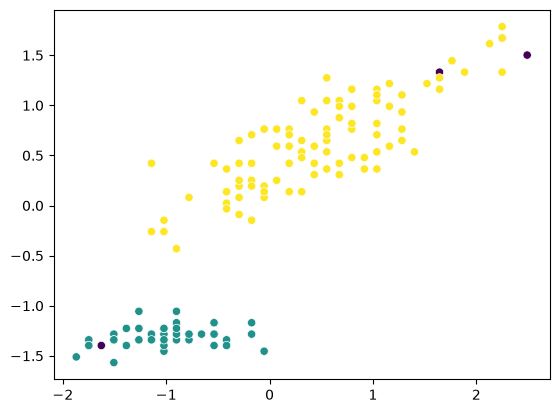

In [7]:
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:,2], c=labels)

### Non-linear data

In [8]:
from sklearn.datasets import make_moons

In [9]:
X, y = make_moons(
    n_samples=300,
    noise=0.07,
    random_state=42
)

<Axes: >

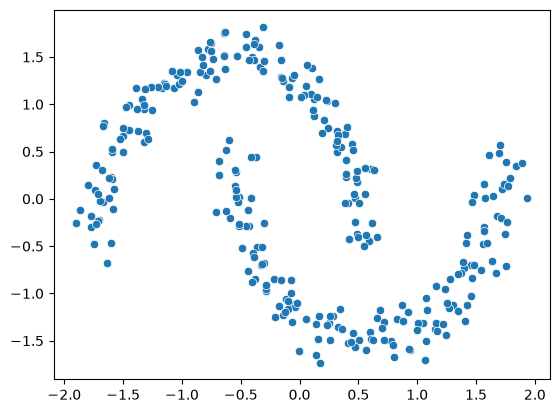

In [10]:
X_scaled = scaler.fit_transform(X)

sns.scatterplot(x=X_scaled[:,0], y=X_scaled[:, 1])

In [11]:
# K-Means
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42
)

labels = kmeans.fit_predict(X_scaled)

<Axes: >

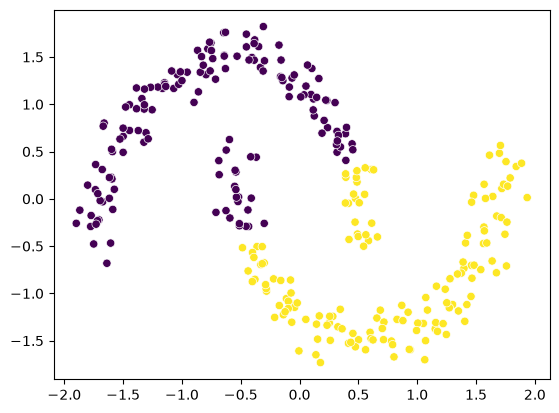

In [12]:
sns.scatterplot(x=X_scaled[:,0], y=X_scaled[:, 1], c=labels)

In [13]:
# DBSCAN

dbscan = DBSCAN(
    eps=0.3,
    min_samples=2
)

labels = dbscan.fit_predict(X_scaled)

<Axes: >

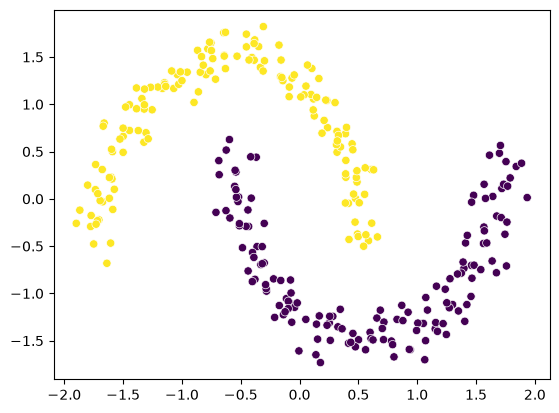

In [14]:
sns.scatterplot(x=X_scaled[:,0], y=X_scaled[:, 1], c=labels)

## K-Means vs DBSCAN on the moons

In [15]:
from sklearn.metrics import adjusted_rand_score
import numpy as np

print("K-Means ARI vs true moons:", adjusted_rand_score(y, kmeans.labels_))
print("DBSCAN  ARI vs true moons:", adjusted_rand_score(y, labels))
print("DBSCAN clusters found:", len(set(labels) - {-1}), "| noise points:", np.sum(labels == -1))

K-Means ARI vs true moons: 0.47896853094705444
DBSCAN  ARI vs true moons: 1.0
DBSCAN clusters found: 2 | noise points: 0
